# Placement 2, part 2: BiomedCoOp on Alzheimer's disease MRI

Here I apply BiomedCoOp to a task it was not designed or tested for: classifying brain MRI slices into four stages of dementia (no dementia, very mild, mild, moderate). Unlike tumours, the stages differ by small, graded changes, mainly how much the brain has shrunk.

The protocol is the same as in the paper and in notebook 1: 1, 2, 4, 8 and 16 labelled images per class, seeds 1, 2 and 3, and the authors' settings. For context I compare with:
* **zero-shot BiomedCLIP**, with no training images, using one template and the average of the 50 LLM descriptions,
* **CoOp**, the prompt learning method BiomedCoOp builds on, without the LLM descriptions,
* **a linear probe**, logistic regression on frozen BiomedCLIP image features, which uses no text.

The classes are very unbalanced (moderate dementia is about 1% of the images), so accuracy alone can be misleading. I also report macro-F1, which gives each stage equal weight, and confusion matrices.



## 1. Setup

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/placement2'
OUTPUTS = f'{PROJECT}/outputs'     # one folder per run, with Dassl's log.txt
RESULTS = f'{PROJECT}/results'
DATA = '/content/data'
BIOMEDCOOP = '/content/BiomedCoOp'
for d in (OUTPUTS, RESULTS, f'{RESULTS}/figures', DATA):
    os.makedirs(d, exist_ok=True)

Mounted at /content/drive


In [ ]:
%%bash
cd /content
if [ ! -d BiomedCoOp ]; then git clone -q https://github.com/HealthX-Lab/BiomedCoOp.git; fi
cd BiomedCoOp
git checkout -q 23710b0b867e8cb4a5ea95b0ccbaa5e35203db0d
echo "BiomedCoOp at commit $(git rev-parse --short HEAD)"
pip install -q yacs gdown ftfy regex tabulate tensorboard timm wilds==1.2.2 open_clip_torch==2.23.0 transformers==4.35.2
sed -i 's/super().__init__(optimizer, last_epoch, verbose)/super().__init__(optimizer, last_epoch)/'     Dassl.pytorch/dassl/optim/lr_scheduler.py
grep -c "super().__init__(optimizer, last_epoch)" Dassl.pytorch/dassl/optim/lr_scheduler.py

cd Dassl.pytorch && python -c "import dassl; print('dassl', dassl.__version__)"
python -c "import torch; print('torch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))"

BiomedCoOp at commit 23710b0
1
dassl 0.5.0
torch 2.14.1+cu130 | GPU: Tesla T4


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.35.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import glob, re, subprocess, sys
import numpy as np
import pandas as pd

SHOTS = [1, 2, 4, 8, 16]   # labelled images per class, as in the paper
DASSL = f'{BIOMEDCOOP}/Dassl.pytorch'
ENV = {**os.environ, 'PYTHONPATH': f"{DASSL}:{BIOMEDCOOP}:{os.environ.get('PYTHONPATH', '')}"}

COMMON_OPTS = ['TEST.COMPUTE_CMAT', 'True', 'TEST.PER_CLASS_RESULT', 'True',
               'DATALOADER.NUM_WORKERS', '2']


def run_finished(out_dir):
    """A run counts as done once its log has a test accuracy in it."""
    for log in glob.glob(f'{out_dir}/log.txt*'):
        if '* accuracy:' in open(log, errors='ignore').read():
            return True
    return False


def run(trainer, dataset_cfg, trainer_cfg, out_dir, shots=None, seed=None,
        opts=(), eval_only=False, script=f'{BIOMEDCOOP}/train.py'):
    """Runs one training/test job with the authors' train.py (or my wrapper).

    Only the result lines are printed here, to keep the notebook readable.
    Dassl writes the full output to log.txt in out_dir."""
    if run_finished(out_dir):
        print(f'already done: {out_dir.replace(OUTPUTS + "/", "")}')
        return
    cmd = [sys.executable, script, '--root', DATA, '--trainer', trainer,
           '--dataset-config-file', dataset_cfg, '--config-file', trainer_cfg,
           '--output-dir', out_dir]
    if seed is not None:
        cmd += ['--seed', str(seed)]
    if eval_only:
        cmd += ['--eval-only']
    cmd += list(opts) + COMMON_OPTS
    if shots is not None:
        cmd += ['DATASET.NUM_SHOTS', str(shots)]

    print(f'\n{out_dir.replace(OUTPUTS + "/", "")}')
    proc = subprocess.Popen(cmd, cwd=BIOMEDCOOP, env=ENV, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)
    tail = []
    for line in proc.stdout:
        tail = (tail + [line])[-40:]
        if line.startswith(('* accuracy', '* macro_f1')):
            print('   ', line.strip())
    if proc.wait() != 0:
        # Stop here instead of carrying on with a broken setup.
        print(''.join(tail))
        raise RuntimeError(f'run failed: {out_dir}')


def read_result(run_dir):
    """Reads the final test metrics back from a run's log."""
    text = ''.join(open(f, errors='ignore').read() for f in sorted(glob.glob(f'{run_dir}/log.txt*')))
    acc = re.findall(r'\* accuracy: ([\d.]+)%', text)
    if not acc:
        return None
    row = {'accuracy': float(acc[-1]),
           'macro_f1': float(re.findall(r'\* macro_f1: ([\d.]+)%', text)[-1])}
    last = text[text.rfind('* macro_f1'):]
    for name, acc_c in re.findall(r'\* class: \d+ \((.+?)\).*?acc: ([\d.]+)%', last):
        row[f'acc_{name}'] = float(acc_c)
    return row


def collect(dataset):
    """All finished runs of one dataset -> (one row per run, mean/std per method and K)."""
    rows = []
    for log in glob.glob(f'{OUTPUTS}/{dataset}/**/log.txt', recursive=True):
        run_dir = os.path.dirname(log)
        res = read_result(run_dir)
        if res is None:
            continue
        parts = os.path.relpath(run_dir, f'{OUTPUTS}/{dataset}').split('/')
        shots = next((int(p[6:]) for p in parts if p.startswith('shots_')), 0)
        seed = next((int(p[4:]) for p in parts if p.startswith('seed')), 0)
        rows.append({'method': parts[0], 'shots': shots, 'seed': seed, **res})
    runs = pd.DataFrame(rows).sort_values(['method', 'shots', 'seed']).reset_index(drop=True)
    metrics = [c for c in runs.columns if c in ('accuracy', 'macro_f1') or c.startswith('acc_')]
    summary = runs.groupby(['method', 'shots'])[metrics].agg(['mean', 'std']).round(2)
    summary.columns = [f'{m}_{s}' for m, s in summary.columns]
    summary.insert(0, 'n_seeds', runs.groupby(['method', 'shots']).size())
    runs.to_csv(f'{RESULTS}/{dataset}_runs.csv', index=False)
    summary.reset_index().to_csv(f'{RESULTS}/{dataset}_summary.csv', index=False)
    return runs, summary.reset_index()

In [ ]:

PAPER = pd.DataFrame([
    # dataset, method, K, mean, std
    ('BTMRI', 'zeroshot', 0, 56.79, np.nan), ('BTMRI', 'zeroshot_ensemble', 0, 61.04, np.nan),
    ('BTMRI', 'biomedcoop', 1, 65.08, 1.81), ('BTMRI', 'biomedcoop', 2, 70.57, 4.31),
    ('BTMRI', 'biomedcoop', 4, 77.23, 3.90), ('BTMRI', 'biomedcoop', 8, 78.55, 2.19),
    ('BTMRI', 'biomedcoop', 16, 83.30, 1.34),
    ('BTMRI', 'coop', 1, 63.82, 3.94), ('BTMRI', 'coop', 2, 68.82, 5.15),
    ('BTMRI', 'coop', 4, 74.68, 2.99), ('BTMRI', 'coop', 8, 79.27, 1.90),
    ('BTMRI', 'coop', 16, 82.37, 1.89),
    ('BTMRI', 'linear_probe', 1, 62.24, 5.03), ('BTMRI', 'linear_probe', 2, 72.45, 5.27),
    ('BTMRI', 'linear_probe', 4, 75.98, 1.94), ('BTMRI', 'linear_probe', 8, 77.63, 3.45),
    ('BTMRI', 'linear_probe', 16, 81.24, 2.56),
    ('KneeXray', 'zeroshot', 0, 29.53, np.nan), ('KneeXray', 'zeroshot_ensemble', 0, 39.37, np.nan),
    ('KneeXray', 'biomedcoop', 1, 36.13, 1.75), ('KneeXray', 'biomedcoop', 2, 37.72, 0.54),
    ('KneeXray', 'biomedcoop', 4, 35.91, 0.54), ('KneeXray', 'biomedcoop', 8, 37.70, 1.00),
    ('KneeXray', 'biomedcoop', 16, 39.69, 1.75),
    ('KneeXray', 'coop', 1, 24.96, 9.41), ('KneeXray', 'coop', 2, 25.89, 5.06),
    ('KneeXray', 'coop', 4, 23.85, 4.25), ('KneeXray', 'coop', 8, 26.23, 4.01),
    ('KneeXray', 'coop', 16, 28.48, 1.84),
    ('KneeXray', 'linear_probe', 1, 26.02, 11.08), ('KneeXray', 'linear_probe', 2, 26.57, 5.17),
    ('KneeXray', 'linear_probe', 4, 27.83, 4.92), ('KneeXray', 'linear_probe', 8, 22.20, 3.68),
    ('KneeXray', 'linear_probe', 16, 23.97, 3.55),
], columns=['dataset', 'method', 'shots', 'accuracy_mean', 'accuracy_std'])
PAPER.to_csv(f'{RESULTS}/paper_reference_results.csv', index=False)

## 2. Data

`Falah/Alzheimer_MRI` on Hugging Face (Apache-2.0): 6,400 axial brain MRI slices of 128×128 pixels in four classes, with an official split of 5,120 training and 1,280 test images. This cell downloads it, saves the images by class, makes the train/val/test split and checks for duplicate images. The class counts and the duplicate check are saved to `results`.

In [ ]:
import glob, hashlib, io, json, random
from collections import Counter, defaultdict
from huggingface_hub import snapshot_download
from PIL import Image

LABEL_MAP = {
    2: (0, 'no_dementia', 'no dementia'),                # Non_Demented
    3: (1, 'very_mild_dementia', 'very mild dementia'),  # Very_Mild_Demented
    0: (2, 'mild_dementia', 'mild dementia'),            # Mild_Demented
    1: (3, 'moderate_dementia', 'moderate dementia'),    # Moderate_Demented
}
STAGES = ['no dementia', 'very mild dementia', 'mild dementia', 'moderate dementia']
VAL_FRACTION, SPLIT_SEED = 0.2, 0

alz_dir = f'{DATA}/ALZMRI'
hf_dir = snapshot_download('Falah/Alzheimer_MRI', repo_type='dataset', allow_patterns=['*.parquet'])

def pixel_hash(img):
    # Hash of the pixels rather than the file, so re-encoded copies still match.
    return hashlib.md5(np.asarray(img.convert('L')).tobytes()).hexdigest()

hashes, sizes, official = {}, Counter(), {}
for part in ('train', 'test'):
    files = sorted(glob.glob(f'{hf_dir}/**/{part}-*.parquet', recursive=True))
    df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
    items = []
    for idx, row in df.iterrows():
        label, folder, name = LABEL_MAP[int(row['label'])]
        img = Image.open(io.BytesIO(row['image']['bytes']))
        rel = f'{folder}/{part}_{idx:04d}.png'
        os.makedirs(f'{alz_dir}/images/{folder}', exist_ok=True)
        img.save(f'{alz_dir}/images/{rel}')
        sizes[img.size] += 1
        hashes[rel] = pixel_hash(img)
        items.append((rel, label, name))
    official[part] = items

by_class = defaultdict(list)
for item in official['train']:
    by_class[item[1]].append(item)
rng = random.Random(SPLIT_SEED)
train, val = [], []
for label in sorted(by_class):
    group = sorted(by_class[label])
    rng.shuffle(group)
    n_val = round(len(group) * VAL_FRACTION)
    val, train = val + group[:n_val], train + group[n_val:]
split = {'train': train, 'val': val, 'test': official['test']}
json.dump(split, open(f'{alz_dir}/split_ALZMRI.json', 'w'), indent=1)

counts = pd.DataFrame({p: Counter(c for _, _, c in items) for p, items in split.items()}).reindex(STAGES)
counts['total'] = counts.sum(axis=1)
counts.loc['total'] = counts.sum()
counts.to_csv(f'{RESULTS}/ALZMRI_class_counts.csv')

train_pool = {hashes[p] for p, _, _ in official['train']}
n_copies = Counter(hashes.values())
checks = {'image_sizes': {f'{w}x{h}': n for (w, h), n in sizes.items()},
          'unique_images': len(n_copies),
          'images_that_have_an_exact_copy': sum(n for n in n_copies.values() if n > 1),
          'test_images_identical_to_a_training_image': sum(hashes[p] in train_pool for p, _, _ in official['test']),
          'test_images': len(official['test'])}
json.dump(checks, open(f'{RESULTS}/ALZMRI_data_checks.json', 'w'), indent=1)
print(counts.to_string(), '\n')
print(checks)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

data/train-00000-of-00001-c08a401c53fe53(…):   0%|          | 0.00/22.6M [00:00<?, ?B/s]

data/test-00000-of-00001-44110b9df98c558(…):   0%|          | 0.00/5.65M [00:00<?, ?B/s]

                    train   val  test  total
no dementia          2053   513   634   3200
very mild dementia   1425   356   459   2240
mild dementia         579   145   172    896
moderate dementia      39    10    15     64
total                4096  1024  1280   6400 

{'image_sizes': {'128x128': 6400}, 'unique_images': 6400, 'images_that_have_an_exact_copy': 0, 'test_images_identical_to_a_training_image': 0, 'test_images': 1280}


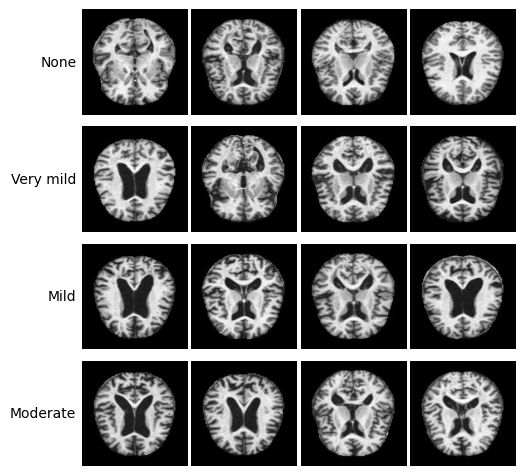

In [ ]:
# Four random training slices per stage, as a figure for the report.
import matplotlib.pyplot as plt
rng_img = np.random.default_rng(0)
fig, axes = plt.subplots(4, 4, figsize=(5.6, 6))
for r, stage in enumerate(STAGES):
    paths = [p for p, _, c in split['train'] if c == stage]
    for c, p in enumerate(rng_img.choice(paths, 4, replace=False)):
        axes[r, c].imshow(plt.imread(f'{alz_dir}/images/{p}'), cmap='gray')
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        for s in axes[r, c].spines.values():
            s.set_visible(False)
    axes[r, 0].set_ylabel(['None', 'Very mild', 'Mild', 'Moderate'][r], rotation=0, ha='right', va='center')
fig.subplots_adjust(wspace=0.04, hspace=0.06)
fig.savefig(f'{RESULTS}/figures/alzmri_examples.png', dpi=300, bbox_inches='tight')
fig.savefig(f'{RESULTS}/figures/alzmri_examples.pdf', bbox_inches='tight')
plt.show()

## 3. LLM descriptions of each stage

BiomedCoOp needs a set of text descriptions for each class (50 in the paper). The authors generated them with GPT-4, using the query:

> Give N textual descriptions of visual discriminative features for distinct medical cases of [CLASS] found in [MODALITY].

I used the same query with N = 50, [MODALITY] = "brain MRI" and [CLASS] = each stage, with Claude (Anthropic) as the LLM. I added one instruction to match the style of the authors' descriptions, which name the modality and end with the class name: *Write each description as one sentence that mentions the MRI and ends by naming the class. The images are single 2D axial slices, so only describe features that can be seen in one axial slice.*

The descriptions were used as generated, and they have not been checked by a radiologist. Because the stages differ in *how much* atrophy there is rather than *where*, the descriptions of different stages describe the same structures (hippocampus, temporal horns, ventricles, sulci) and differ mostly in words like "slight", "clear", "marked" and "severe".

In [ ]:
# 50 descriptions per stage, generated with the query described above.
DESCRIPTIONS = {
    "no dementia": [
        "An axial brain MRI showing full, rounded hippocampi with narrow temporal horns, indicating no dementia.",
        "A brain MRI slice with tightly packed cortical gyri and thin sulci across both hemispheres, consistent with no dementia.",
        "An MRI of the brain with small, slit-like lateral ventricles and no enlargement of the temporal horns, suggesting no dementia.",
        "An axial MRI showing a thick, well-preserved cortical ribbon in the temporal and parietal lobes, indicating no dementia.",
        "A brain MRI with a narrow Sylvian fissure and no widening of the space around the medial temporal lobe, consistent with no dementia.",
        "An MRI slice of the brain where the medial temporal lobe fills its space with little surrounding cerebrospinal fluid, suggesting no dementia.",
        "An axial brain MRI with symmetrical hemispheres, normal-sized ventricles and no visible tissue loss, indicating no dementia.",
        "A brain MRI showing only mild, age-appropriate sulcal widening with preserved hippocampal volume, consistent with no dementia.",
        "An MRI of the brain in which the gray matter is evenly thick and the white matter appears full and uniform, suggesting no dementia.",
        "An axial MRI slice showing a compact third ventricle and closely opposed frontal and temporal gyri, indicating no dementia.",
        "A brain MRI with clearly defined hippocampal heads and no dark fluid gap between the hippocampus and the brainstem, consistent with no dementia.",
        "An MRI of the brain showing narrow cortical sulci over the parietal lobes and no posterior atrophy, suggesting no dementia.",
        "An axial brain MRI in which the brain tissue fills most of the skull with only a thin rim of surrounding fluid, indicating no dementia.",
        "A brain MRI slice with small frontal horns of the lateral ventricles and a normal caudate outline, consistent with no dementia.",
        "An MRI showing intact entorhinal and parahippocampal cortex with no thinning of the medial temporal lobe, suggesting no dementia.",
        "An axial brain MRI with sharply defined gray-white matter boundaries and no areas of cortical thinning, indicating no dementia.",
        "A brain MRI with temporal lobes of normal size and a narrow temporal horn on both sides, consistent with no dementia.",
        "An MRI of the brain showing a normal width of the interhemispheric fissure and full frontal lobes, suggesting no dementia.",
        "An axial MRI slice in which the ventricles are small relative to the surrounding brain tissue, indicating no dementia.",
        "A brain MRI showing a normal precuneus and posterior cingulate region with tight sulci, consistent with no dementia.",
        "An MRI of the brain with no hippocampal shrinkage and a choroidal fissure that is barely visible, suggesting no dementia.",
        "An axial brain MRI showing healthy brain volume for age, with no ventricular or sulcal enlargement, indicating no dementia.",
        "A brain MRI slice with evenly spaced gyri and no deepening of the sulci in the temporal or parietal cortex, consistent with no dementia.",
        "An MRI of the brain with an intact insular cortex and a closed Sylvian fissure, suggesting no dementia.",
        "An axial MRI showing symmetrical medial temporal lobes of normal height on both sides, indicating no dementia.",
        "A brain MRI with a smooth, normal ventricular outline and no rounding or ballooning of the ventricles, consistent with no dementia.",
        "An MRI slice of the brain in which the cortex appears full in all lobes, with no regional pattern of tissue loss, suggesting no dementia.",
        "An axial brain MRI showing a small amount of cerebrospinal fluid over the convexities and in the basal cisterns, indicating no dementia.",
        "A brain MRI with well-preserved white matter volume and a normally thick corpus callosum, consistent with no dementia.",
        "An MRI of the brain showing hippocampi of normal shape with a clear internal structure, suggesting no dementia.",
        "An axial MRI slice with narrow sulci and plump gyri in the frontal, temporal and parietal lobes, indicating no dementia.",
        "A brain MRI showing no widening of the perihippocampal fissures and no enlargement of the temporal horns, consistent with no dementia.",
        "An MRI of the brain with a normal brain-to-fluid ratio and no global loss of brain volume, suggesting no dementia.",
        "An axial brain MRI in which the lateral ventricles are narrow and do not extend into enlarged temporal horns, indicating no dementia.",
        "A brain MRI slice showing a normal thickness of the parietal cortex with no posterior predominant atrophy, consistent with no dementia.",
        "An MRI showing no visible shrinkage of the medial temporal lobe and preserved amygdala volume, suggesting no dementia.",
        "An axial MRI of the brain with compact ventricles, thin sulci and a normal Sylvian fissure, indicating no dementia.",
        "A brain MRI showing the typical brain shape of a healthy older adult with only minimal sulcal prominence, consistent with no dementia.",
        "An MRI slice of the brain with intact cortical folding and no flattening or thinning of the gyri, suggesting no dementia.",
        "An axial brain MRI with symmetrical, normal-sized ventricles and no asymmetric temporal atrophy, indicating no dementia.",
        "A brain MRI showing normal hippocampal width and a well-defined collateral sulcus, consistent with no dementia.",
        "An MRI of the brain in which the space between the brain surface and the skull is narrow, suggesting no dementia.",
        "An axial MRI slice showing a normal-sized third ventricle and closely spaced thalami, indicating no dementia.",
        "A brain MRI with uniform gray matter signal and no regions of reduced cortical volume, consistent with no dementia.",
        "An MRI of the brain showing preserved temporal lobe volume with no widening of the temporal sulci, suggesting no dementia.",
        "An axial brain MRI in which the frontal horns are small and the caudate heads keep their normal convex shape, indicating no dementia.",
        "A brain MRI slice with no medial temporal lobe atrophy on visual rating and normal ventricular size, consistent with no dementia.",
        "An MRI showing full cerebral hemispheres with a thin layer of fluid in the sulci, suggesting no dementia.",
        "An axial brain MRI with normal volume in the hippocampus, entorhinal cortex and temporal neocortex, indicating no dementia.",
        "A brain MRI showing a healthy, age-appropriate brain with no pattern of atrophy typical of Alzheimer's disease, consistent with no dementia."
    ],
    "very mild dementia": [
        "An axial brain MRI showing slight narrowing of the hippocampi with early widening of the temporal horns, indicating very mild dementia.",
        "A brain MRI slice with subtle thinning of the medial temporal lobe and a slightly more visible choroidal fissure, consistent with very mild dementia.",
        "An MRI of the brain showing mildly widened sulci in the temporal lobes while the rest of the cortex looks largely preserved, suggesting very mild dementia.",
        "An axial MRI with a small increase in cerebrospinal fluid around the hippocampi compared with a healthy brain, indicating very mild dementia.",
        "A brain MRI showing early, subtle volume loss in the entorhinal cortex with otherwise near-normal brain structure, consistent with very mild dementia.",
        "An MRI slice of the brain with slightly enlarged lateral ventricles and minimal sulcal widening, suggesting very mild dementia.",
        "An axial brain MRI showing a faint widening of the Sylvian fissures and the temporal sulci, indicating very mild dementia.",
        "A brain MRI with mild hippocampal volume loss that is only just visible on an axial slice, consistent with very mild dementia.",
        "An MRI of the brain showing early thinning of the parietal cortex with slightly deeper sulci over the precuneus, suggesting very mild dementia.",
        "An axial MRI slice in which the temporal horns are slightly larger than expected for age, indicating very mild dementia.",
        "A brain MRI showing borderline medial temporal lobe atrophy with a small dark gap next to the hippocampus, consistent with very mild dementia.",
        "An MRI of the brain with mild, diffuse sulcal prominence slightly beyond what is typical for age, suggesting very mild dementia.",
        "An axial brain MRI showing early asymmetric shrinkage of one hippocampus with the other still near normal, indicating very mild dementia.",
        "A brain MRI slice with slightly rounded frontal horns and a marginally widened third ventricle, consistent with very mild dementia.",
        "An MRI showing subtle loss of temporal lobe volume, with gyri that look slightly thinner than in a healthy brain, suggesting very mild dementia.",
        "An axial brain MRI with a thin but visible rim of extra fluid along the medial temporal lobes, indicating very mild dementia.",
        "A brain MRI showing a mild increase in the size of the lateral ventricles while the cortex remains mostly intact, consistent with very mild dementia.",
        "An MRI of the brain in which the hippocampal head appears slightly flattened, suggesting very mild dementia.",
        "An axial MRI slice showing early widening of the posterior cingulate and parietal sulci, indicating very mild dementia.",
        "A brain MRI with slight enlargement of the perihippocampal fissures and the temporal horn, consistent with very mild dementia.",
        "An MRI of the brain showing a small reduction in overall brain volume relative to the skull, suggesting very mild dementia.",
        "An axial brain MRI with faint cortical thinning in the temporal and parietal lobes and preserved frontal lobes, indicating very mild dementia.",
        "A brain MRI slice in which the medial temporal lobe looks slightly smaller than normal on visual rating, consistent with very mild dementia.",
        "An MRI showing mild opening of the Sylvian fissure and slight thinning of the insular cortex, suggesting very mild dementia.",
        "An axial MRI of the brain showing early ventricular enlargement with the temporal horns starting to open up, indicating very mild dementia.",
        "A brain MRI with gyri that are slightly narrower and sulci that are slightly wider than expected for age, consistent with very mild dementia.",
        "An MRI of the brain showing subtle volume loss in the parahippocampal gyrus with an otherwise normal-looking slice, suggesting very mild dementia.",
        "An axial brain MRI with a mild increase of fluid in the basal cisterns around the medial temporal lobes, indicating very mild dementia.",
        "A brain MRI slice showing early hippocampal atrophy that is easy to miss without comparison to a healthy scan, consistent with very mild dementia.",
        "An MRI showing slightly deepened temporal sulci and a mildly prominent collateral sulcus, suggesting very mild dementia.",
        "An axial brain MRI in which the lateral ventricles are just above normal size for an older adult, indicating very mild dementia.",
        "A brain MRI showing a subtle pattern of temporoparietal volume loss with preserved occipital lobes, consistent with very mild dementia.",
        "An MRI of the brain with slight thinning of the cortical ribbon in the medial temporal region, suggesting very mild dementia.",
        "An axial MRI slice showing a narrow but visible fluid space separating the hippocampus from surrounding structures, indicating very mild dementia.",
        "A brain MRI with mild widening of the interhemispheric fissure and slight frontal sulcal prominence, consistent with very mild dementia.",
        "An MRI of the brain showing early shrinkage of the amygdala and hippocampus with mild temporal horn dilation, suggesting very mild dementia.",
        "An axial brain MRI with slightly more cerebrospinal fluid over the convexities than in a healthy brain of the same age, indicating very mild dementia.",
        "A brain MRI slice showing minimal but definite hippocampal volume loss on both sides, consistent with very mild dementia.",
        "An MRI showing a slightly enlarged choroidal fissure and early thinning of the medial temporal cortex, suggesting very mild dementia.",
        "An axial MRI of the brain with mild ventricular rounding and slight widening of the cortical sulci, indicating very mild dementia.",
        "A brain MRI showing early posterior cortical thinning around the precuneus with near-normal hippocampi, consistent with very mild dementia.",
        "An MRI of the brain in which the temporal lobes look marginally smaller than the frontal lobes would suggest, suggesting very mild dementia.",
        "An axial brain MRI showing faint widening of the sulci between the temporal gyri, indicating very mild dementia.",
        "A brain MRI slice with a small increase in temporal horn width and slight hippocampal flattening, consistent with very mild dementia.",
        "An MRI showing early, mild global atrophy with slightly enlarged ventricles and sulci, suggesting very mild dementia.",
        "An axial MRI of the brain with subtle entorhinal and hippocampal volume loss and a preserved cortex elsewhere, indicating very mild dementia.",
        "A brain MRI showing mild medial temporal lobe atrophy, rated as just above normal on a visual scale, consistent with very mild dementia.",
        "An MRI of the brain with slightly widened parietal and temporal sulci and a mildly open Sylvian fissure, suggesting very mild dementia.",
        "An axial brain MRI in which the brain still looks largely normal apart from early hippocampal shrinkage, indicating very mild dementia.",
        "A brain MRI showing the earliest visible stage of the atrophy pattern of Alzheimer's disease, centred on the medial temporal lobe, consistent with very mild dementia."
    ],
    "mild dementia": [
        "An axial brain MRI showing clear shrinkage of both hippocampi with widened temporal horns, indicating mild dementia.",
        "A brain MRI slice with obvious medial temporal lobe atrophy and an enlarged choroidal fissure, consistent with mild dementia.",
        "An MRI of the brain showing moderately enlarged lateral ventricles and widened cortical sulci, suggesting mild dementia.",
        "An axial MRI with a clear gap of cerebrospinal fluid around the shrunken hippocampi, indicating mild dementia.",
        "A brain MRI showing visible thinning of the temporal and parietal cortex with deepened sulci, consistent with mild dementia.",
        "An MRI slice of the brain with a widened Sylvian fissure and visible loss of temporal lobe volume, suggesting mild dementia.",
        "An axial brain MRI showing enlarged temporal horns that are clearly visible next to atrophic hippocampi, indicating mild dementia.",
        "A brain MRI with definite hippocampal atrophy and moderate widening of the sulci over both hemispheres, consistent with mild dementia.",
        "An MRI of the brain showing clear parietal atrophy with widened sulci around the precuneus and posterior cingulate, suggesting mild dementia.",
        "An axial MRI slice in which the lateral ventricles are noticeably larger than normal for age, indicating mild dementia.",
        "A brain MRI showing medial temporal lobe atrophy that is easy to see on an axial slice, with thin parahippocampal gyri, consistent with mild dementia.",
        "An MRI of the brain with moderate global atrophy, enlarged ventricles and more fluid between the gyri, suggesting mild dementia.",
        "An axial brain MRI showing shrunken temporal lobes with widened temporal sulci on both sides, indicating mild dementia.",
        "A brain MRI slice with enlarged frontal horns and a widened third ventricle, consistent with mild dementia.",
        "An MRI showing clear volume loss in the hippocampus, amygdala and entorhinal cortex, suggesting mild dementia.",
        "An axial brain MRI with thin, narrow gyri separated by wide sulci in the temporal and parietal lobes, indicating mild dementia.",
        "A brain MRI showing a temporoparietal pattern of atrophy with relatively preserved occipital and sensorimotor cortex, consistent with mild dementia.",
        "An MRI of the brain in which the hippocampal head is visibly small and surrounded by enlarged fluid spaces, suggesting mild dementia.",
        "An axial MRI slice showing a widened interhemispheric fissure and frontal sulcal enlargement in addition to temporal atrophy, indicating mild dementia.",
        "A brain MRI with clearly dilated temporal horns and widened perihippocampal fissures, consistent with mild dementia.",
        "An MRI of the brain showing a reduced brain-to-skull ratio with more cerebrospinal fluid over the brain surface, suggesting mild dementia.",
        "An axial brain MRI with moderate thinning of the cortical ribbon in the temporal lobes, indicating mild dementia.",
        "A brain MRI slice in which the medial temporal lobe atrophy is rated as moderate on a visual scale, consistent with mild dementia.",
        "An MRI showing a clearly open Sylvian fissure and thinning of the insula, suggesting mild dementia.",
        "An axial MRI of the brain with rounded, enlarged lateral ventricles and visible periventricular tissue loss, indicating mild dementia.",
        "A brain MRI showing wider sulci and thinner gyri than in very mild disease, with clear hippocampal shrinkage, consistent with mild dementia.",
        "An MRI of the brain showing atrophy of the parahippocampal gyrus with a prominent collateral sulcus, suggesting mild dementia.",
        "An axial brain MRI with enlarged basal cisterns around atrophic medial temporal lobes, indicating mild dementia.",
        "A brain MRI slice showing hippocampal atrophy on both sides that is clearly visible without comparison images, consistent with mild dementia.",
        "An MRI showing deepened and widened sulci between the temporal gyri with reduced temporal lobe bulk, suggesting mild dementia.",
        "An axial brain MRI in which the lateral ventricles take up a noticeably larger part of the slice, indicating mild dementia.",
        "A brain MRI showing moderate posterior cortical atrophy around the precuneus and parietal lobes, consistent with mild dementia.",
        "An MRI of the brain with clear loss of cortical thickness in the medial temporal region and an enlarged temporal horn, suggesting mild dementia.",
        "An axial MRI slice showing a wide fluid space separating the shrunken hippocampus from the brainstem, indicating mild dementia.",
        "A brain MRI with moderate frontal and temporal sulcal widening and a slightly thinned corpus callosum, consistent with mild dementia.",
        "An MRI of the brain showing visible shrinkage of the amygdala and hippocampus with dilated temporal horns, suggesting mild dementia.",
        "An axial brain MRI with a clear rim of cerebrospinal fluid over the convexities and widened sulci, indicating mild dementia.",
        "A brain MRI slice showing definite bilateral hippocampal volume loss, more marked than in very mild disease, consistent with mild dementia.",
        "An MRI showing an enlarged choroidal fissure and clear thinning of the medial temporal cortex, suggesting mild dementia.",
        "An axial MRI of the brain with enlarged, rounded ventricles and moderately widened cortical sulci, indicating mild dementia.",
        "A brain MRI showing clear posterior cingulate and parietal atrophy together with hippocampal shrinkage, consistent with mild dementia.",
        "An MRI of the brain in which the temporal lobes look clearly smaller than in a healthy older adult, suggesting mild dementia.",
        "An axial brain MRI showing widened sulci between thin temporal gyri and an open Sylvian fissure, indicating mild dementia.",
        "A brain MRI slice with enlarged temporal horns and flattened, atrophic hippocampi, consistent with mild dementia.",
        "An MRI showing moderate global atrophy with enlarged ventricles and sulci beyond what is expected for age, suggesting mild dementia.",
        "An axial MRI of the brain with clear entorhinal and hippocampal volume loss and early thinning of the neocortex, indicating mild dementia.",
        "A brain MRI showing moderate medial temporal lobe atrophy on visual rating together with ventricular enlargement, consistent with mild dementia.",
        "An MRI of the brain with widened parietal and temporal sulci and a clearly enlarged Sylvian fissure, suggesting mild dementia.",
        "An axial brain MRI in which the atrophy of the medial temporal lobes has spread to the temporal and parietal cortex, indicating mild dementia.",
        "A brain MRI showing a clear Alzheimer's disease pattern of atrophy in the hippocampus and temporoparietal cortex, consistent with mild dementia."
    ],
    "moderate dementia": [
        "An axial brain MRI showing severe shrinkage of both hippocampi with markedly enlarged temporal horns, indicating moderate dementia.",
        "A brain MRI slice with marked medial temporal lobe atrophy and a very wide choroidal fissure, consistent with moderate dementia.",
        "An MRI of the brain showing greatly enlarged lateral ventricles and widely open cortical sulci, suggesting moderate dementia.",
        "An axial MRI with large spaces of cerebrospinal fluid where the hippocampi have shrunk away, indicating moderate dementia.",
        "A brain MRI showing severe thinning of the temporal and parietal cortex with deep, wide sulci, consistent with moderate dementia.",
        "An MRI slice of the brain with a very wide Sylvian fissure and marked loss of temporal lobe volume, suggesting moderate dementia.",
        "An axial brain MRI showing ballooned temporal horns and very small, atrophic hippocampi, indicating moderate dementia.",
        "A brain MRI with severe hippocampal atrophy and marked widening of the sulci across the whole brain, consistent with moderate dementia.",
        "An MRI of the brain showing marked parietal atrophy with widely separated gyri around the precuneus, suggesting moderate dementia.",
        "An axial MRI slice in which the lateral ventricles are greatly enlarged and dominate the centre of the slice, indicating moderate dementia.",
        "A brain MRI showing severe medial temporal lobe atrophy, with the parahippocampal gyri reduced to thin strips, consistent with moderate dementia.",
        "An MRI of the brain with marked global atrophy, very large ventricles and abundant fluid between the gyri, suggesting moderate dementia.",
        "An axial brain MRI showing shrunken temporal lobes with very wide temporal sulci on both sides, indicating moderate dementia.",
        "A brain MRI slice with markedly enlarged frontal horns and a wide third ventricle, consistent with moderate dementia.",
        "An MRI showing severe volume loss in the hippocampus, amygdala and entorhinal cortex, suggesting moderate dementia.",
        "An axial brain MRI with thin, shrunken gyri separated by very wide sulci in the temporal, parietal and frontal lobes, indicating moderate dementia.",
        "A brain MRI showing widespread atrophy that now also involves the frontal lobes in addition to the temporoparietal cortex, consistent with moderate dementia.",
        "An MRI of the brain in which the hippocampal region is mostly replaced by enlarged fluid spaces, suggesting moderate dementia.",
        "An axial MRI slice showing a very wide interhemispheric fissure and marked frontal sulcal enlargement, indicating moderate dementia.",
        "A brain MRI with greatly dilated temporal horns and wide perihippocampal fissures, consistent with moderate dementia.",
        "An MRI of the brain showing a much reduced brain volume within the skull, with a thick layer of surrounding cerebrospinal fluid, suggesting moderate dementia.",
        "An axial brain MRI with severe thinning of the cortical ribbon throughout the temporal lobes, indicating moderate dementia.",
        "A brain MRI slice in which the medial temporal lobe atrophy is rated as severe on a visual scale, consistent with moderate dementia.",
        "An MRI showing a widely open Sylvian fissure and marked thinning of the insular cortex, suggesting moderate dementia.",
        "An axial MRI of the brain with large, rounded lateral ventricles and clear loss of periventricular white matter, indicating moderate dementia.",
        "A brain MRI showing much wider sulci and thinner gyri than in mild disease, with severe hippocampal shrinkage, consistent with moderate dementia.",
        "An MRI of the brain showing severe atrophy of the parahippocampal gyrus with a deep, wide collateral sulcus, suggesting moderate dementia.",
        "An axial brain MRI with markedly enlarged basal cisterns around severely atrophic medial temporal lobes, indicating moderate dementia.",
        "A brain MRI slice showing severe bilateral hippocampal atrophy that is obvious at first glance, consistent with moderate dementia.",
        "An MRI showing very deep and wide sulci between the temporal gyri with greatly reduced temporal lobe bulk, suggesting moderate dementia.",
        "An axial brain MRI in which the enlarged lateral ventricles take up a large part of the brain area on the slice, indicating moderate dementia.",
        "A brain MRI showing marked posterior cortical atrophy of the precuneus and parietal lobes, consistent with moderate dementia.",
        "An MRI of the brain with severe loss of cortical thickness in the medial temporal region and a ballooned temporal horn, suggesting moderate dementia.",
        "An axial MRI slice showing a very wide fluid space between the shrunken medial temporal lobe and the brainstem, indicating moderate dementia.",
        "A brain MRI with marked frontal and temporal sulcal widening and a visibly thin corpus callosum, consistent with moderate dementia.",
        "An MRI of the brain showing severe shrinkage of the amygdala and hippocampus with greatly dilated temporal horns, suggesting moderate dementia.",
        "An axial brain MRI with a thick rim of cerebrospinal fluid over the convexities and very wide sulci, indicating moderate dementia.",
        "A brain MRI slice showing severe bilateral hippocampal volume loss, much more marked than in mild disease, consistent with moderate dementia.",
        "An MRI showing a greatly enlarged choroidal fissure and severe thinning of the medial temporal cortex, suggesting moderate dementia.",
        "An axial MRI of the brain with markedly enlarged ventricles and widely open sulci over both hemispheres, indicating moderate dementia.",
        "A brain MRI showing severe posterior cingulate and parietal atrophy together with marked hippocampal shrinkage, consistent with moderate dementia.",
        "An MRI of the brain in which the temporal lobes are markedly smaller than normal and separated from the skull by wide fluid spaces, suggesting moderate dementia.",
        "An axial brain MRI showing very wide sulci between thin temporal gyri and a widely open Sylvian fissure, indicating moderate dementia.",
        "A brain MRI slice with ballooned temporal horns and severely flattened, atrophic hippocampi, consistent with moderate dementia.",
        "An MRI showing marked global atrophy with greatly enlarged ventricles and sulci far beyond what is expected for age, suggesting moderate dementia.",
        "An axial MRI of the brain with severe entorhinal and hippocampal volume loss and clear thinning of the whole neocortex, indicating moderate dementia.",
        "A brain MRI showing severe medial temporal lobe atrophy on visual rating together with marked ventricular enlargement, consistent with moderate dementia.",
        "An MRI of the brain with very wide parietal, temporal and frontal sulci and a greatly enlarged Sylvian fissure, suggesting moderate dementia.",
        "An axial brain MRI in which atrophy has spread from the medial temporal lobes to most of the cerebral cortex, indicating moderate dementia.",
        "A brain MRI showing an advanced Alzheimer's disease pattern of widespread atrophy with severe hippocampal loss, consistent with moderate dementia."
    ]
}

# Quick checks: 50 unique sentences per class, each ending with the class name.
for name, sents in DESCRIPTIONS.items():
    assert len(set(sents)) == 50 and all(s.rstrip('.').endswith(name) for s in sents), name
os.makedirs('/content/alz_ext', exist_ok=True)
for path in ('/content/alz_ext/alzheimer_descriptions.json', f'{RESULTS}/alzheimer_descriptions.json'):
    json.dump(DESCRIPTIONS, open(path, 'w'), indent=1)
print('saved', {k: len(v) for k, v in DESCRIPTIONS.items()})

saved {'no dementia': 50, 'very mild dementia': 50, 'mild dementia': 50, 'moderate dementia': 50}


## 4. Adding the dataset to BiomedCoOp

Three small files: the dataset class, a wrapper that registers it before running the authors' `train.py`, and the config files. The authors' code itself is not changed.

In [ ]:
%%writefile /content/alz_ext/alzheimer_ext.py
"""Adds my Alzheimer dataset and its descriptions to BiomedCoOp.

BiomedCoOp finds datasets through Dassl's registry, which is filled when
train.py imports them, and reads the LLM descriptions from a dictionary in
trainers/prompt_templates.py. I add both at run time instead of editing the
authors' files, so their code stays exactly as published.
"""
import json
import os
import pickle

from dassl.data.datasets import DATASET_REGISTRY, DatasetBase
from dassl.utils import mkdir_if_missing

from datasets.btmri import BTMRI

HERE = os.path.dirname(os.path.abspath(__file__))
CLASSNAMES = ['no dementia', 'very mild dementia', 'mild dementia', 'moderate dementia']


@DATASET_REGISTRY.register()
class ALZMRI(BTMRI):
    """Same loading and few-shot sampling as the authors' BTMRI class (I inherit
    it), only the paths differ. So any difference between the BTMRI and the
    Alzheimer results comes from the data, not from a different loader."""

    dataset_dir = 'ALZMRI'

    def __init__(self, cfg):
        root = os.path.abspath(os.path.expanduser(cfg.DATASET.ROOT))
        self.dataset_dir = os.path.join(root, self.dataset_dir)
        self.image_dir = os.path.join(self.dataset_dir, 'images')
        self.split_path = os.path.join(self.dataset_dir, 'split_ALZMRI.json')
        self.split_fewshot_dir = os.path.join(self.dataset_dir, 'split_fewshot')
        mkdir_if_missing(self.split_fewshot_dir)

        # The split is made once in the notebook, never randomly here, so it is the same for every method and run.
        train, val, test = self.read_split(self.split_path, self.image_dir)

        num_shots = cfg.DATASET.NUM_SHOTS
        if num_shots >= 1:
            # The K-shot sample for each seed is saved the first time it is drawn, so all methods train on exactly the same images.
            cache = os.path.join(self.split_fewshot_dir, f'shot_{num_shots}-seed_{cfg.SEED}.pkl')
            if os.path.exists(cache):
                with open(cache, 'rb') as f:
                    data = pickle.load(f)
                train, val = data['train'], data['val']
            else:
                train = self.generate_fewshot_dataset(train, num_shots=num_shots)
                val = self.generate_fewshot_dataset(val, num_shots=min(num_shots, 4))
                with open(cache, 'wb') as f:
                    pickle.dump({'train': train, 'val': val}, f, protocol=pickle.HIGHEST_PROTOCOL)

        train, val, test = self.subsample_classes(train, val, test, subsample=cfg.DATASET.SUBSAMPLE_CLASSES)
        DatasetBase.__init__(self, train_x=train, val=val, test=test)


def register():
    from trainers import prompt_templates

    prompt_templates.CUSTOM_TEMPLATES['ALZMRI'] = 'a photo of a {}.'
    descriptions = json.load(open(os.path.join(HERE, 'alzheimer_descriptions.json')))
    for name in CLASSNAMES:

        old = prompt_templates.BIOMEDCOOP_TEMPLATES.get(name)
        assert old is None or old == descriptions[name], f'{name} already exists'
        prompt_templates.BIOMEDCOOP_TEMPLATES[name] = descriptions[name]

Writing /content/alz_ext/alzheimer_ext.py


In [ ]:
%%writefile /content/alz_ext/train_alz.py
"""Registers my dataset, then runs the authors' train.py exactly as if it had
been called from the command line (same arguments)."""
import os, runpy, sys

BIOMEDCOOP = '/content/BiomedCoOp'
os.chdir(BIOMEDCOOP)                      # train.py uses relative imports and paths
sys.path[:0] = ['/content/alz_ext', BIOMEDCOOP, f'{BIOMEDCOOP}/Dassl.pytorch']

import alzheimer_ext
alzheimer_ext.register()

sys.argv[0] = f'{BIOMEDCOOP}/train.py'
runpy.run_path(sys.argv[0], run_name='__main__')

Writing /content/alz_ext/train_alz.py


In [ ]:
import shutil
CFG_DIR = '/content/alz_ext/configs'
os.makedirs(CFG_DIR, exist_ok=True)
open(f'{CFG_DIR}/alzmri.yaml', 'w').write('DATASET:\n  NAME: "ALZMRI"\n')
shutil.copy(f'{BIOMEDCOOP}/configs/trainers/BiomedCoOp/few_shot/btmri.yaml', f'{CFG_DIR}/biomedcoop_alzmri.yaml')
shutil.copy(f'{BIOMEDCOOP}/configs/trainers/BiomedCoOp/few_shot/kneexray.yaml', f'{CFG_DIR}/biomedcoop_alzmri_knee.yaml')
for f in ('biomedcoop_alzmri.yaml', 'biomedcoop_alzmri_knee.yaml'):
    shutil.copy(f'{CFG_DIR}/{f}', f'{RESULTS}/{f}')     # keep a copy with the records

DATASET_CFG = f'{CFG_DIR}/alzmri.yaml'
BIOMEDCOOP_CFG = f'{CFG_DIR}/biomedcoop_alzmri.yaml'
BIOMEDCOOP_KNEE_CFG = f'{CFG_DIR}/biomedcoop_alzmri_knee.yaml'
ZEROSHOT_CFG = f'{BIOMEDCOOP}/configs/trainers/Zeroshot/vit_b16.yaml'
COOP_CFG = f'{BIOMEDCOOP}/configs/trainers/CoOp/vit_b16.yaml'
BIOMEDCOOP_OPTS = ['TRAINER.BIOMEDCOOP.N_CTX', '4', 'TRAINER.BIOMEDCOOP.CSC', 'False',
                   'TRAINER.BIOMEDCOOP.CLASS_TOKEN_POSITION', 'end']
COOP_OPTS = ['TRAINER.COOP.N_CTX', '4', 'TRAINER.COOP.CSC', 'False',
             'TRAINER.COOP.CLASS_TOKEN_POSITION', 'end']
WRAPPER = '/content/alz_ext/train_alz.py'
SEEDS = [1, 2, 3]


fewshot_drive = f'{OUTPUTS}/ALZMRI_fewshot_samples'
os.makedirs(fewshot_drive, exist_ok=True)
link = f'{alz_dir}/split_fewshot'
if not os.path.islink(link):
    shutil.rmtree(link, ignore_errors=True)
    os.symlink(fewshot_drive, link)
print('ready')

ready


## 5. Zero-shot BiomedCLIP



In [ ]:
run('ZeroshotBiomedCLIP', DATASET_CFG, ZEROSHOT_CFG, f'{OUTPUTS}/ALZMRI/zeroshot',
    eval_only=True, script=WRAPPER)
run('ZeroshotBiomedCLIP2', DATASET_CFG, ZEROSHOT_CFG, f'{OUTPUTS}/ALZMRI/zeroshot_ensemble',
    eval_only=True, script=WRAPPER)


ALZMRI/zeroshot
    * accuracy: 13.52%
    * macro_f1: 6.04%

ALZMRI/zeroshot_ensemble
    * accuracy: 41.17%
    * macro_f1: 21.33%


## 6. BiomedCoOp



In [ ]:
for k in SHOTS:
    for seed in SEEDS:
        run('BiomedCoOp_BiomedCLIP', DATASET_CFG, BIOMEDCOOP_CFG,
            f'{OUTPUTS}/ALZMRI/biomedcoop/shots_{k}/seed{seed}',
            shots=k, seed=seed, opts=BIOMEDCOOP_OPTS, script=WRAPPER)


ALZMRI/biomedcoop/shots_1/seed1
    * accuracy: 29.61%
    * macro_f1: 17.32%

ALZMRI/biomedcoop/shots_1/seed2
    * accuracy: 29.45%
    * macro_f1: 24.39%

ALZMRI/biomedcoop/shots_1/seed3
    * accuracy: 40.31%
    * macro_f1: 19.84%

ALZMRI/biomedcoop/shots_2/seed1
    * accuracy: 38.05%
    * macro_f1: 24.60%

ALZMRI/biomedcoop/shots_2/seed2
    * accuracy: 35.39%
    * macro_f1: 25.88%

ALZMRI/biomedcoop/shots_2/seed3
    * accuracy: 44.53%
    * macro_f1: 25.67%

ALZMRI/biomedcoop/shots_4/seed1
    * accuracy: 43.59%
    * macro_f1: 22.01%

ALZMRI/biomedcoop/shots_4/seed2
    * accuracy: 44.22%
    * macro_f1: 25.29%

ALZMRI/biomedcoop/shots_4/seed3
    * accuracy: 48.05%
    * macro_f1: 28.67%

ALZMRI/biomedcoop/shots_8/seed1
    * accuracy: 28.44%
    * macro_f1: 17.50%

ALZMRI/biomedcoop/shots_8/seed2
    * accuracy: 34.53%
    * macro_f1: 25.68%

ALZMRI/biomedcoop/shots_8/seed3
    * accuracy: 28.28%
    * macro_f1: 19.87%

ALZMRI/biomedcoop/shots_16/seed1
    * accuracy: 45

check ups

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import json, pandas as pd
from huggingface_hub import hf_hub_download

RESULTS = '/content/drive/MyDrive/placement2/results'
OUTPUTS = '/content/drive/MyDrive/placement2/outputs'

# 1a. What the dataset itself says the label numbers mean.
readme = open(hf_hub_download('Falah/Alzheimer_MRI', 'README.md', repo_type='dataset')).read()
print(readme[:1500])

# 1b. How many images ended up in each stage (my mapping).
print(pd.read_csv(f'{RESULTS}/ALZMRI_class_counts.csv', index_col=0))
print(json.load(open(f'{RESULTS}/ALZMRI_data_checks.json')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


README.md: 0.00B [00:00, ?B/s]

---
dataset_info:
  features:
  - name: image
    dtype: image
  - name: label
    dtype:
      class_label:
        names:
          '0': Mild_Demented
          '1': Moderate_Demented
          '2': Non_Demented
          '3': Very_Mild_Demented
  splits:
  - name: train
    num_bytes: 22560791.2
    num_examples: 5120
  - name: test
    num_bytes: 5637447.08
    num_examples: 1280
  download_size: 28289848
  dataset_size: 28198238.28
license: apache-2.0
task_categories:
- image-classification
language:
- en
tags:
- medical
pretty_name: Alzheimer_MRI Disease Classification Dataset
size_categories:
- 1K<n<10K
---
# Alzheimer_MRI Disease Classification Dataset

The Falah/Alzheimer_MRI Disease Classification dataset is a valuable resource for researchers and health medicine applications. This dataset focuses on the classification of Alzheimer's disease based on MRI scans. The dataset consists of brain MRI images labeled into four categories:

- '0': Mild_Demented
- '1': Moderate_Demente

In [ ]:
import glob, numpy as np, torch
STAGES = ['None', 'Very mild', 'Mild', 'Moderate']

def show(title, files):
    mats = [np.asarray(torch.load(f, weights_only=False, map_location='cpu')) for f in files]
    if mats:
        cm = pd.DataFrame(np.mean(mats, axis=0) * 100, index=STAGES, columns=STAGES).round(0)
        print(f'\n{title}  (rows = true stage, % of that stage)\n{cm}')

show('Zero-shot + descriptions', glob.glob(f'{OUTPUTS}/ALZMRI/zeroshot_ensemble/cmat.pt'))
for k in [1, 2, 4, 8, 16]:
    show(f'BiomedCoOp, K={k}', glob.glob(f'{OUTPUTS}/ALZMRI/biomedcoop/shots_{k}/seed*/cmat.pt'))


Zero-shot + descriptions  (rows = true stage, % of that stage)
           None  Very mild  Mild  Moderate
None       62.0       35.0   0.0       4.0
Very mild  65.0       29.0   0.0       5.0
Mild       62.0       32.0   0.0       6.0
Moderate   60.0       40.0   0.0       0.0

BiomedCoOp, K=1  (rows = true stage, % of that stage)
           None  Very mild  Mild  Moderate
None       15.0       60.0  18.0       7.0
Very mild  11.0       63.0  16.0      10.0
Mild        9.0       58.0  21.0      12.0
Moderate   18.0       44.0  24.0      13.0

BiomedCoOp, K=2  (rows = true stage, % of that stage)
           None  Very mild  Mild  Moderate
None       39.0       51.0  10.0       0.0
Very mild  38.0       52.0  10.0       0.0
Mild       40.0       47.0  13.0       0.0
Moderate   51.0       27.0  20.0       2.0

BiomedCoOp, K=4  (rows = true stage, % of that stage)
           None  Very mild  Mild  Moderate
None       68.0       28.0   3.0       1.0
Very mild  64.0       29.0   4.0       2

In [ ]:
!pip install -q open_clip_torch

import glob, io, numpy as np, pandas as pd, torch
from PIL import Image
from huggingface_hub import snapshot_download
from open_clip import create_model_from_pretrained
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

STAGES = ['None', 'Very mild', 'Mild', 'Moderate']
HF_TO_STAGE = {2: 0, 3: 1, 0: 2, 1: 3}   # same mapping as in the main notebook

hf_dir = snapshot_download('Falah/Alzheimer_MRI', repo_type='dataset', allow_patterns=['*.parquet'])
def load(part):
    df = pd.concat([pd.read_parquet(f) for f in sorted(glob.glob(f'{hf_dir}/**/{part}-*.parquet', recursive=True))])
    imgs = [Image.open(io.BytesIO(b['bytes'])).convert('RGB') for b in df['image']]
    return imgs, np.array([HF_TO_STAGE[int(l)] for l in df['label']])
train_imgs, y_train = load('train')
test_imgs, y_test = load('test')

def report(name, pred):
    cm = pd.DataFrame(confusion_matrix(y_test, pred, normalize='true') * 100, index=STAGES, columns=STAGES).round(0)
    print(f'\n{name}: accuracy {100*accuracy_score(y_test, pred):.1f}%, '
          f'macro-F1 {100*f1_score(y_test, pred, average="macro"):.1f}%\n{cm}')

# (1) Raw pixels: each slice shrunk to 64x64 greyscale and flattened.
px = lambda imgs: np.stack([np.asarray(i.convert('L').resize((64, 64)), dtype=np.float32).ravel() / 255 for i in imgs])
scaler = StandardScaler().fit(px(train_imgs))
clf = LogisticRegressionCV(Cs=8, max_iter=3000, n_jobs=-1).fit(scaler.transform(px(train_imgs)), y_train)
report('Raw pixels, full training set', clf.predict(scaler.transform(px(test_imgs))))

# (2) Frozen BiomedCLIP image features (same model as BiomedCoOp).
model, preprocess = create_model_from_pretrained('hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224')
model.eval()
@torch.no_grad()
def feats(imgs):
    out = []
    for i in range(0, len(imgs), 64):
        f = model.encode_image(torch.stack([preprocess(x) for x in imgs[i:i+64]]))
        out.append(torch.nn.functional.normalize(f, dim=-1).numpy())
    return np.concatenate(out)
f_train, f_test = feats(train_imgs), feats(test_imgs)
np.savez('/content/drive/MyDrive/placement2/results/biomedclip_features.npz',
         f_train=f_train, y_train=y_train, f_test=f_test, y_test=y_test)

clf = LogisticRegressionCV(Cs=8, max_iter=3000, n_jobs=-1).fit(f_train, y_train)
report('BiomedCLIP features, full training set', clf.predict(f_test))

# (3) Same features, only 16 images per stage (3 random draws), to see the effect of few labels.
for seed in (1, 2, 3):
    rng = np.random.default_rng(seed)
    idx = np.concatenate([rng.choice(np.where(y_train == c)[0], 16, replace=False) for c in range(4)])
    clf = LogisticRegressionCV(Cs=8, cv=3, max_iter=3000).fit(f_train[idx], y_train[idx])
    report(f'BiomedCLIP features, 16 per stage (seed {seed})', clf.predict(f_test))

/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]


Raw pixels, full training set: accuracy 92.5%, macro-F1 92.1%
           None  Very mild  Mild  Moderate
None       95.0        4.0   0.0       0.0
Very mild   7.0       91.0   2.0       0.0
Mild        7.0        5.0  88.0       0.0
Moderate    0.0       13.0   0.0      87.0


/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(



BiomedCLIP features, full training set: accuracy 61.2%, macro-F1 44.0%
           None  Very mild  Mild  Moderate
None       79.0       17.0   4.0       0.0
Very mild  47.0       50.0   4.0       0.0
Mild       24.0       45.0  31.0       0.0
Moderate   13.0       67.0  13.0       7.0

BiomedCLIP features, 16 per stage (seed 1): accuracy 37.8%, macro-F1 32.6%
           None  Very mild  Mild  Moderate
None       36.0       35.0  18.0      11.0
Very mild  29.0       34.0  25.0      13.0
Mild       17.0       21.0  49.0      13.0
Moderate    0.0        0.0  13.0      87.0

BiomedCLIP features, 16 per stage (seed 2): accuracy 42.6%, macro-F1 33.8%
           None  Very mild  Mild  Moderate
None       50.0       22.0  19.0       9.0
Very mild  29.0       36.0  24.0      11.0
Mild       15.0       42.0  32.0      10.0
Moderate    0.0       13.0   7.0      80.0

BiomedCLIP features, 16 per stage (seed 3): accuracy 41.0%, macro-F1 32.3%
           None  Very mild  Mild  Moderate
None       5

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
X_train_px, X_test_px = scaler.transform(px(train_imgs)), scaler.transform(px(test_imgs))
for name, (Xtr, Xte) in {'raw pixels': (X_train_px, X_test_px),
                         'BiomedCLIP features': (f_train, f_test)}.items():
    knn = KNeighborsClassifier(n_neighbors=1).fit(Xtr, y_train)
    report(f'1-nearest neighbour on {name}', knn.predict(Xte))


1-nearest neighbour on raw pixels: accuracy 99.5%, macro-F1 99.5%
            None  Very mild  Mild  Moderate
None       100.0        0.0   0.0       0.0
Very mild    1.0       99.0   0.0       0.0
Mild         1.0        1.0  98.0       0.0
Moderate     0.0        0.0   0.0     100.0

1-nearest neighbour on BiomedCLIP features: accuracy 98.1%, macro-F1 97.4%
           None  Very mild  Mild  Moderate
None       99.0        1.0   0.0       0.0
Very mild   1.0       99.0   0.0       0.0
Mild        3.0        2.0  95.0       0.0
Moderate    0.0        0.0   7.0      93.0


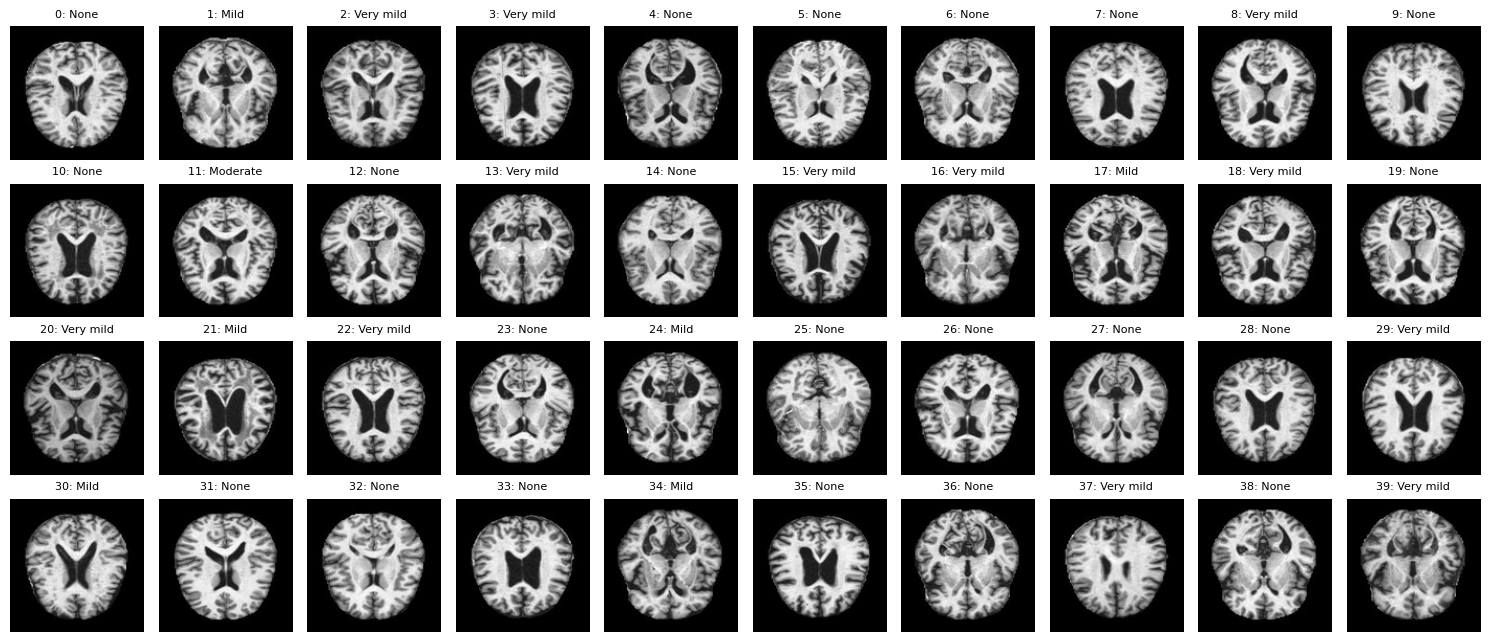

first 64 labels in file order: [0, 2, 1, 1, 0, 0, 0, 0, 1, 0, 0, 3, 0, 1, 0, 1, 1, 2, 1, 0, 1, 2, 1, 0, 2, 0, 0, 0, 0, 1, 2, 0, 0, 0, 2, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0]


In [ ]:

import matplotlib.pyplot as plt
fig, axes = plt.subplots(4, 10, figsize=(15, 6.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_imgs[i].convert('L'), cmap='gray')
    ax.set_title(f'{i}: {STAGES[y_train[i]]}', fontsize=8)
    ax.axis('off')
plt.tight_layout(); plt.show()
print('first 64 labels in file order:', y_train[:64].tolist())

In [ ]:
from sklearn.cluster import AgglomerativeClustering

X_all = {'raw pixels': np.concatenate([X_train_px, X_test_px]),
         'BiomedCLIP features': np.concatenate([f_train, f_test])}
y_all = np.concatenate([y_train, y_test])
in_test = np.r_[np.zeros(len(y_train), bool), np.ones(len(y_test), bool)]

groups = {}
for name, X in X_all.items():
    print(f'\n=== {name} ===')
    g = np.full(len(y_all), -1)
    offset = 0
    for c in range(4):
        idx = np.where(y_all == c)[0]
        n = len(idx) // 32
        cl = AgglomerativeClustering(n_clusters=n, linkage='single').fit_predict(X[idx])
        g[idx] = cl + offset
        offset += n
        sizes = np.bincount(cl)
        print(f'{STAGES[c]:>9}: {n} clusters | sizes min {sizes.min()}, median {int(np.median(sizes))}, '
              f'max {sizes.max()} | exactly 32: {(sizes == 32).sum()}/{n}')
    groups[name] = g
    # How many recovered "people" have slices in both the training and the test set?
    both = sum(in_test[g == k].any() and (~in_test[g == k]).any() for k in np.unique(g))
    print(f'clusters with slices in both train and test: {both}/{len(np.unique(g))}')


=== raw pixels ===
     None: 100 clusters | sizes min 1, median 1, max 2344 | exactly 32: 8/100
Very mild: 70 clusters | sizes min 1, median 1, max 1569 | exactly 32: 7/70
     Mild: 28 clusters | sizes min 1, median 1, max 562 | exactly 32: 6/28
 Moderate: 2 clusters | sizes min 1, median 32, max 63 | exactly 32: 0/2
clusters with slices in both train and test: 69/200

=== BiomedCLIP features ===
     None: 100 clusters | sizes min 1, median 1, max 2983 | exactly 32: 0/100
Very mild: 70 clusters | sizes min 1, median 1, max 2067 | exactly 32: 0/70
     Mild: 28 clusters | sizes min 1, median 2, max 802 | exactly 32: 0/28
 Moderate: 2 clusters | sizes min 2, median 32, max 62 | exactly 32: 0/2
clusters with slices in both train and test: 52/200


## 7. Baselines

### CoOp

In [ ]:
for k in SHOTS:
    for seed in SEEDS:
        run('CoOp_BiomedCLIP', DATASET_CFG, COOP_CFG,
            f'{OUTPUTS}/ALZMRI/coop/shots_{k}/seed{seed}',
            shots=k, seed=seed, opts=COOP_OPTS, script=WRAPPER)

### Linear probe


In [ ]:
%%writefile /content/alz_ext/linear_probe.py
"""Linear probe on frozen BiomedCLIP image features.

The image encoder stays frozen and only a logistic regression is trained on its
features, so the text side of the model isn't used at all. This shows whether
BiomedCoOp's prompts add anything over the image features alone.

I wrote my own instead of using the authors' linear probe (main.py), because
theirs only reports accuracy and draws its few-shot samples separately. Here I
load the same cached K-shot images that BiomedCoOp and CoOp trained on and
write the result in the same format as Dassl, so all methods are compared on
equal terms. The setup follows the CLIP paper (Radford et al., 2021):
L2-normalised features, logistic regression, and C chosen on the validation
images (min(K, 4) per class, as in Dassl).
"""
import os, sys
import numpy as np
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score

BIOMEDCOOP = '/content/BiomedCoOp'
os.chdir(BIOMEDCOOP)
sys.path[:0] = ['/content/alz_ext', BIOMEDCOOP, f'{BIOMEDCOOP}/Dassl.pytorch']
import alzheimer_ext
alzheimer_ext.register()
from dassl.config import get_cfg_default
from dassl.data.datasets import build_dataset
from dassl.utils import read_image, set_random_seed
from open_clip.src.open_clip import create_model_from_pretrained  # the authors' copy of open_clip

DATA, OUT = sys.argv[1], sys.argv[2]
SHOTS, SEEDS = [1, 2, 4, 8, 16], [1, 2, 3]
C_GRID = np.logspace(-2, 4, 13)   # 0.01 ... 10,000

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, preprocess = create_model_from_pretrained('hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224')
model.eval().to(device)


def dataset(shots, seed):
    # Built the same way as in train.py, so the cached K-shot sample is reused.
    cfg = get_cfg_default()
    cfg.DATASET.NAME, cfg.DATASET.ROOT = 'ALZMRI', DATA
    cfg.DATASET.NUM_SHOTS, cfg.DATASET.SUBSAMPLE_CLASSES, cfg.SEED = shots, 'all', seed
    set_random_seed(seed)
    return build_dataset(cfg)


@torch.no_grad()
def features(items):
    feats = []
    for i in range(0, len(items), 128):
        x = torch.stack([preprocess(read_image(it.impath)) for it in items[i:i + 128]]).to(device)
        feats.append(torch.nn.functional.normalize(model.encode_image(x), dim=-1).cpu())
    return torch.cat(feats).numpy(), np.array([it.label for it in items])


full = dataset(-1, 1)
x_test, y_test = features(full.test)          # same test set for every run
names = full.classnames

for k in SHOTS:
    for seed in SEEDS:
        out = f'{OUT}/shots_{k}/seed{seed}'
        if os.path.exists(f'{out}/log.txt'):
            continue
        ds = dataset(k, seed)
        x_tr, y_tr = features(ds.train_x)
        x_val, y_val = features(ds.val)
        # Choose C on the validation images, then refit. Ties go to the smaller
        # C (stronger regularisation), the safer choice with this little data.
        scores = [(LogisticRegression(C=c, max_iter=5000).fit(x_tr, y_tr).score(x_val, y_val), -c) for c in C_GRID]
        best_c = -max(scores)[1]
        pred = LogisticRegression(C=best_c, max_iter=5000).fit(x_tr, y_tr).predict(x_test)

        acc = 100 * (pred == y_test).mean()
        f1 = 100 * f1_score(y_test, pred, average='macro')
        lines = [f'Linear probe, C = {best_c:g}', '=> result', f'* accuracy: {acc:.2f}%', f'* macro_f1: {f1:.2f}%',
                 '=> per-class result']
        for c, name in enumerate(names):
            m = y_test == c
            lines.append(f'* class: {c} ({name})\ttotal: {m.sum()}\tcorrect: {(pred[m] == c).sum()}\t'
                         f'acc: {100 * (pred[m] == c).mean():.2f}%')
        os.makedirs(out, exist_ok=True)
        open(f'{out}/log.txt', 'w').write('\n'.join(lines) + '\n')
        torch.save(confusion_matrix(y_test, pred, labels=range(len(names)), normalize='true'), f'{out}/cmat.pt')
        print(f'K={k} seed={seed}: accuracy {acc:.2f}%  macro-F1 {f1:.2f}%  (C={best_c:g})')

In [ ]:
!python /content/alz_ext/linear_probe.py {DATA} {OUTPUTS}/ALZMRI/linear_probe

##  Results

In [ ]:
runs, summary = collect('ALZMRI')
show = summary[['method', 'shots', 'n_seeds', 'accuracy_mean', 'accuracy_std', 'macro_f1_mean', 'macro_f1_std']]

# The main results table: accuracy and macro-F1 as mean ± std, methods as rows.
fmt = lambda m, s: f'{m:.1f}' if np.isnan(s) else f'{m:.1f} ± {s:.1f}'
table = show.assign(acc=[fmt(m, s) for m, s in zip(show.accuracy_mean, show.accuracy_std)],
                    f1=[fmt(m, s) for m, s in zip(show.macro_f1_mean, show.macro_f1_std)])
table = table.pivot(index='method', columns='shots', values=['acc', 'f1'])
table.to_csv(f'{RESULTS}/ALZMRI_main_table.csv')
table

In [ ]:
# Software and hardware used, for the Methods section.
import platform, torch, torchvision, transformers, sklearn
versions = {
    'Python': platform.python_version(),
    'PyTorch': torch.__version__,
    'torchvision': torchvision.__version__,
    'transformers': transformers.__version__,
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'GPU': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none',
    'BiomedCoOp commit': subprocess.run(['git', '-C', BIOMEDCOOP, 'rev-parse', 'HEAD'],
                                        capture_output=True, text=True).stdout.strip(),
}
pd.Series(versions).to_csv(f'{RESULTS}/software_versions.csv', header=False)
pd.Series(versions)

In [ ]:
import matplotlib.pyplot as plt

INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e4e3df'
STYLE = {  # method: (label, colour, marker)
    'biomedcoop': ('BiomedCoOp', '#2a78d6', 'o'),
    'coop': ('CoOp', '#eb6834', 's'),
    'linear_probe': ('Linear probe', '#1baf7a', '^'),
    'biomedcoop_knee_settings': ('BiomedCoOp (KneeXray weights)', '#6250d6', 'D'),
}
plt.rcParams.update({
    'font.size': 9, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK2,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titlesize': 10, 'axes.titleweight': 'bold',
    'axes.titlecolor': INK, 'legend.frameon': False, 'savefig.dpi': 300,
    'savefig.bbox': 'tight'})


def shots_axis(ax):
    ax.grid(axis='y', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.set_xscale('log', base=2)
    ax.set_xticks(SHOTS, [str(k) for k in SHOTS])
    ax.set_xlabel('Labelled images per class (K)')


def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(f'{RESULTS}/figures/{name}.{ext}')
    plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.0), sharex=True)
for ax, metric, ylabel in [(axes[0], 'accuracy', 'Accuracy (%)'), (axes[1], 'macro_f1', 'Macro-F1 (%)')]:
    for method, (label, colour, marker) in STYLE.items():
        d = summary[(summary.method == method) & (summary.shots > 0)]
        if d.empty:
            continue
        mean, std = d[f'{metric}_mean'], d[f'{metric}_std'].fillna(0)
        ax.plot(d.shots, mean, color=colour, marker=marker, markersize=5, linewidth=2, label=label)
        ax.fill_between(d.shots, mean - std, mean + std, color=colour, alpha=0.12, linewidth=0)
    for method, ls, label in [('zeroshot', ':', 'Zero-shot (one template)'),
                              ('zeroshot_ensemble', '--', 'Zero-shot (50 descriptions)')]:
        z = summary[summary.method == method]
        if not z.empty:
            ax.axhline(z[f'{metric}_mean'].iloc[0], color=MUTED, linestyle=ls, linewidth=1.2, label=label)
    shots_axis(ax)
    ax.set_ylabel(ylabel)
axes[0].set_title('Alzheimer MRI: four-stage classification', loc='left')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.13), fontsize=8)
fig.tight_layout()
save(fig, 'alzmri_shots')

In [ ]:
SHORT = ['None', 'Very mild', 'Mild', 'Moderate']

def mean_cmat(method, k):
    mats = [np.asarray(torch.load(f, weights_only=False))
            for f in glob.glob(f'{OUTPUTS}/ALZMRI/{method}/shots_{k}/seed*/cmat.pt')]
    return np.mean(mats, axis=0) if mats else None

import torch
for k in (16, 4):
    found = [(m, mean_cmat(m, k)) for m in ('biomedcoop', 'coop', 'linear_probe')]
    found = [(m, c) for m, c in found if c is not None]
    if not found:
        continue
    fig, axes = plt.subplots(1, len(found), figsize=(2.7 * len(found) + 0.6, 2.8))
    axes = np.atleast_1d(axes)
    for ax, (method, cm) in zip(axes, found):
        im = ax.imshow(cm * 100, cmap='Blues', vmin=0, vmax=100)
        for i in range(4):
            for j in range(4):
                v = cm[i, j] * 100
                ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > 55 else INK)
        ax.set_xticks(range(4), SHORT, rotation=35, ha='right')
        ax.set_yticks(range(4), SHORT if ax is axes[0] else [])
        ax.set_xlabel('Predicted')
        ax.set_title(f'{STYLE[method][0]}, K={k}', loc='left')
        for s in ax.spines.values():
            s.set_visible(False)
    axes[0].set_ylabel('True stage')
    cbar = fig.colorbar(im, ax=list(axes), fraction=0.025, pad=0.02)
    cbar.set_label('% of true stage', color=INK2)
    cbar.outline.set_visible(False)
    save(fig, f'alzmri_confusion_{k}shot')

In [ ]:
cols = [f'acc_{s}' for s in STAGES]
d = runs[(runs.method == 'biomedcoop') & (runs.shots > 0)].groupby('shots')[cols].mean()
fig, ax = plt.subplots(figsize=(4.6, 3.0))
for col, label, colour, mk in zip(cols, SHORT, ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b'], 'os^D'):
    ax.plot(d.index, d[col], color=colour, marker=mk, markersize=5, linewidth=2, label=label)
shots_axis(ax)
ax.set_ylim(-3, 103)
ax.set_ylabel('Recall within stage (%)')
ax.set_title('BiomedCoOp: accuracy within each stage', loc='left')
ax.legend(fontsize=8, ncol=2)
save(fig, 'alzmri_per_class')

In [ ]:
fig, ax = plt.subplots(figsize=(5.2, 3.3))
lines = [('BTMRI, tumour type (paper)', PAPER[PAPER.dataset == 'BTMRI'], '#2a78d6', '--', 'white'),
         ('KneeXray, OA grade (paper)', PAPER[PAPER.dataset == 'KneeXray'], '#eda100', '--', 'white')]
if os.path.exists(f'{RESULTS}/BTMRI_summary.csv'):
    lines.append(('BTMRI (this study)', pd.read_csv(f'{RESULTS}/BTMRI_summary.csv'), '#2a78d6', '-', None))
lines.append(('Alzheimer MRI, dementia stage (this study)', summary, '#e34948', '-', None))
for label, df, colour, ls, face in lines:
    d = df[(df.method == 'biomedcoop') & (df.shots > 0)].sort_values('shots')
    ax.plot(d.shots, d.accuracy_mean, color=colour, linestyle=ls, marker='o', markersize=5,
            linewidth=2, markerfacecolor=face or colour, label=label)
shots_axis(ax)
ax.set_ylabel('BiomedCoOp accuracy (%)')
ax.set_title('BiomedCoOp across tasks', loc='left')
ax.legend(fontsize=7.5)
save(fig, 'biomedcoop_across_tasks')

All tables and figures are saved in `placement2/results` on Drive, and the full logs of every run in `placement2/outputs/ALZMRI`.